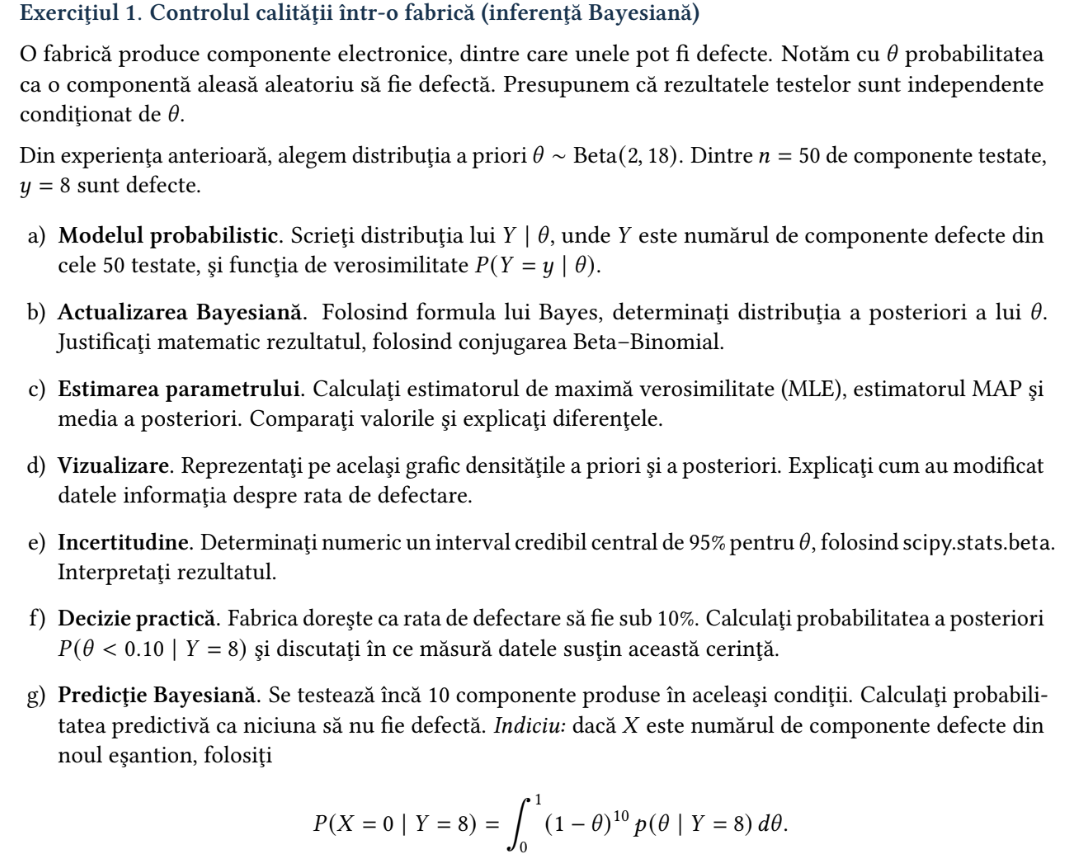

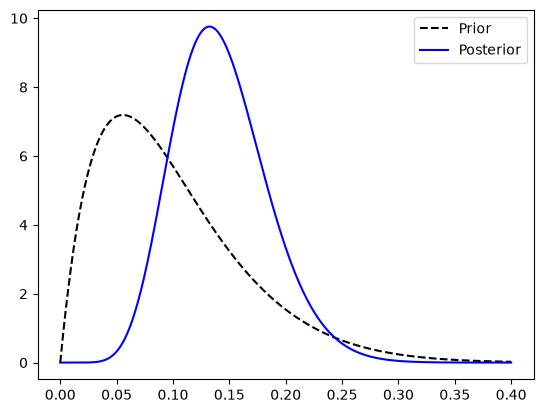

e): [0.0717, 0.2332]
f): 0.1484 (14.84%)
g): 0.2360 (23.60%)


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
from scipy.integrate import quad

a_prior = 2
b_prior = 18

n = 50
y = 8

a_post = a_prior + y       # 10
b_post = b_prior + n - y   # 60



x = np.linspace(0, 0.4, 500)
pdf_prior = beta.pdf(x, a_prior, b_prior)
pdf_post = beta.pdf(x, a_post, b_post)

plt.plot(x, pdf_prior, 'k--', label='Prior')
plt.plot(x, pdf_post, 'b-', label='Posterior')
plt.legend()
plt.show()


limita_inf, limita_sup = beta.interval(0.95, a_post, b_post)

print(f"e): [{limita_inf:.4f}, {limita_sup:.4f}]")


prob_sub_10 = beta.cdf(0.10, a_post, b_post)

print(f"f): {prob_sub_10:.4f} ({prob_sub_10 * 100:.2f}%)")


def integrand_predictiv(theta):
    return ((1 - theta)**10) * beta.pdf(theta, a_post, b_post)

prob_predictiva, eroare_estimata = quad(integrand_predictiv, 0, 1)

print(f"g): {prob_predictiva:.4f} ({prob_predictiva * 100:.2f}%)")

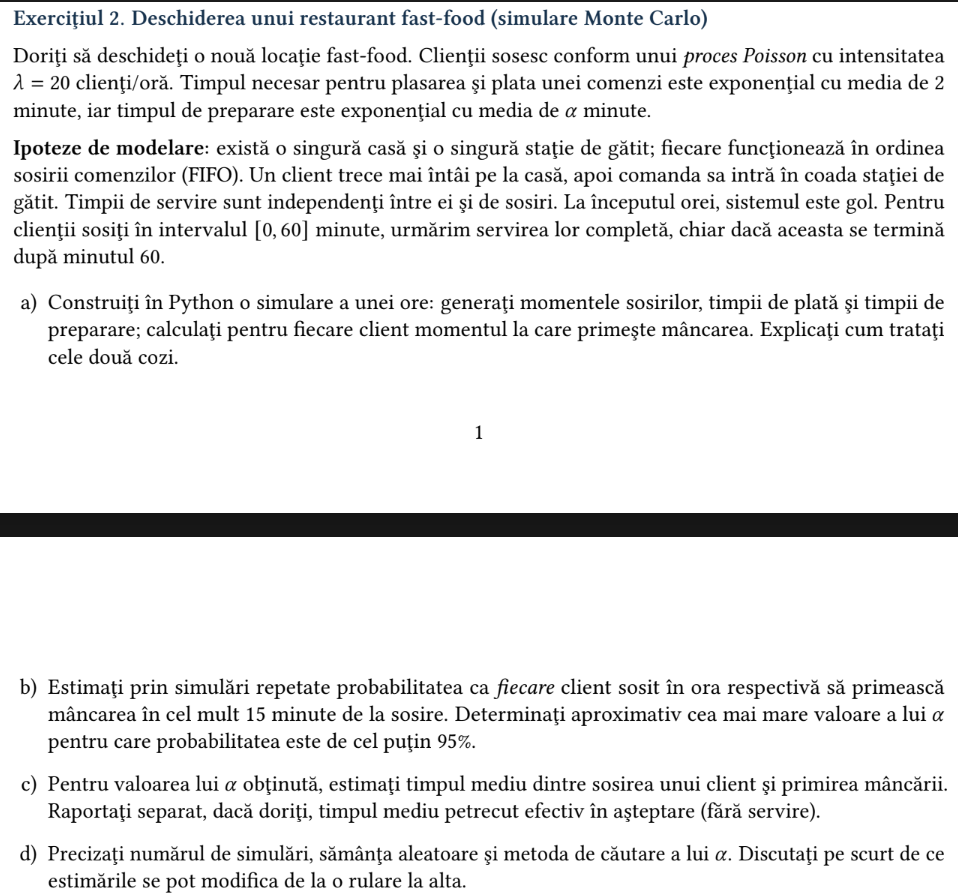

In [7]:
import numpy as np

#a
def simuleaza_ora(alpha):
    timpi_inter_sosiri = []
    timp_curent = 0
    

    while True:
        dt = np.random.exponential(3)
        timp_curent += dt
        if timp_curent > 60:
            break
        timpi_inter_sosiri.append(dt)
        
    N = len(timpi_inter_sosiri)
    if N == 0:
        return [], []
        
    momente_sosire = np.cumsum(timpi_inter_sosiri)
    
    timpi_plata = np.random.exponential(2, N)
    timpi_preparare = np.random.exponential(alpha, N)
    
    end_casa = np.zeros(N)
    end_gatit = np.zeros(N)
    
    for i in range(N):
        if i == 0:
            start_casa = momente_sosire[i]
        else:
            start_casa = max(momente_sosire[i], end_casa[i-1])
        end_casa[i] = start_casa + timpi_plata[i]
        
        if i == 0:
            start_gatit = end_casa[i]
        else:
            start_gatit = max(end_casa[i], end_gatit[i-1])
        end_gatit[i] = start_gatit + timpi_preparare[i]
        
    timpi_totali = end_gatit - momente_sosire
    timpi_asteptare = timpi_totali - timpi_plata - timpi_preparare
    
    return timpi_totali, timpi_asteptare


np.random.seed(42)

num_simulari = 5000  


# b
valori_alpha = np.arange(0.1, 2.1, 0.1)
alpha_optim = None
probabilitate_maxima = 0
cel_mai_bun_alpha = 0.1

for alpha in valori_alpha:
    succese = 0
    for _ in range(num_simulari):
        timpi_totali, _ = simuleaza_ora(alpha)
        if len(timpi_totali) == 0 or np.max(timpi_totali) <= 15:
            succese += 1
            
    probabilitate = succese / num_simulari
    print(f"{alpha=}, {probabilitate=}")

    if probabilitate > probabilitate_maxima:
        probabilitate_maxima = probabilitate
        cel_mai_bun_alpha = alpha
    
    if probabilitate >= 0.95:
        alpha_optim = alpha
        break


    if alpha_optim is None:
        print(f"{cel_mai_bun_alpha=}")
        alpha_optim = cel_mai_bun_alpha
    else:
        print(f"{alpha_optim=}")


#c
timpii_totali = []
timpii_asteptare = []

for _ in range(num_simulari):
    t_tot, t_ast = simuleaza_ora(alpha_optim)
    timpii_totali.extend(t_tot)
    timpii_asteptare.extend(t_ast)

timp_mediu_total = np.mean(timpii_totali)
timp_mediu_asteptare = np.mean(timpii_asteptare)

print(f"{timp_mediu_total=}")
print(f"{timp_mediu_asteptare=}")

alpha=np.float64(0.1), probabilitate=0.8188
cel_mai_bun_alpha=np.float64(0.1)
alpha=np.float64(0.2), probabilitate=0.8122
alpha_optim=np.float64(0.1)
alpha=np.float64(0.30000000000000004), probabilitate=0.7864
alpha_optim=np.float64(0.1)
alpha=np.float64(0.4), probabilitate=0.7952
alpha_optim=np.float64(0.1)
alpha=np.float64(0.5), probabilitate=0.7846
alpha_optim=np.float64(0.1)
alpha=np.float64(0.6), probabilitate=0.7708
alpha_optim=np.float64(0.1)
alpha=np.float64(0.7000000000000001), probabilitate=0.7664
alpha_optim=np.float64(0.1)
alpha=np.float64(0.8), probabilitate=0.7622
alpha_optim=np.float64(0.1)
alpha=np.float64(0.9), probabilitate=0.7488
alpha_optim=np.float64(0.1)
alpha=np.float64(1.0), probabilitate=0.7488
alpha_optim=np.float64(0.1)
alpha=np.float64(1.1), probabilitate=0.73
alpha_optim=np.float64(0.1)
alpha=np.float64(1.2000000000000002), probabilitate=0.711
alpha_optim=np.float64(0.1)
alpha=np.float64(1.3000000000000003), probabilitate=0.6766
alpha_optim=np.float64(0.1)


5000 simulari, seed 42 - secventa generat e tot itmpul aceeasi
cautarea lui alfa e liniara, incepand de la 0.1 cu pas 0.1

Monte Carlo se bazeaza pe esantionare din distributii probabilistice => nedeterminist